# Part I: modeling the housing price

In [ ]:
import pandas as pd
import numpy as np 
from scipy import stats
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split 
from sklearn.linear_model import LinearRegression, Ridge, Lasso 
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
import random
import copy

# Data Preparation

In [ ]:
df = pd.read_csv("data_CASE_group_18.csv")

print (df.shape)
print(df.describe()) 

(2467, 39)
              Price         Area  No. of Bedrooms       Resale  \
count  2.467000e+03  2467.000000      2467.000000  2467.000000   
mean   9.803732e+06  1643.473044         2.625861     0.226996   
std    8.680468e+06   730.814725         0.679819     0.418975   
min    2.000000e+06   500.000000         1.000000     0.000000   
25%    4.760000e+06  1163.000000         2.000000     0.000000   
50%    7.800000e+06  1500.000000         3.000000     0.000000   
75%    1.090000e+07  1830.000000         3.000000     0.000000   
max    1.650000e+08  8500.000000         8.000000     1.000000   

       MaintenanceStaff    Gymnasium  SwimmingPool  LandscapedGardens  \
count       2467.000000  2467.000000   2467.000000        2467.000000   
mean           0.419133     0.746251      0.715444           0.624645   
std            1.641985     1.625421      1.629792           1.639242   
min            0.000000     0.000000      0.000000           0.000000   
25%            0.000000     0

Observe that some of the binary data has 9 as the max value

In [ ]:
# We see that the data contains 0,1,9 

df['MaintenanceStaff'].unique()

# We can infer that the 9 in this instance is missing data 
cols = df.columns[4:39]
df[cols] = df[cols].astype(float).replace(9, np.nan)


# We see that all the binary variables have the same amount of missing variable, so we check that the same rows are missing every column 

is_missing = df[cols].isna()
missing_per_row = is_missing.sum(axis=1)
print(missing_per_row.value_counts().sort_index())

is_missing.all(axis=1).sum()   # rows missing in every column
is_missing.any(axis=1).sum()   # rows missing in at least one column

# We confirmed that the missing data is pretty much all or nothing, before dropping this data it is important to check if the data is statistically different

df['all_missing'] = df[cols].isna().all(axis=1)

vars_ = ['Price', 'Area', 'No. of Bedrooms']

comparison = df.groupby('all_missing')[vars_].mean().T
comparison.columns = ['Complete', 'Missing']        
comparison['Difference'] = comparison['Missing'] - comparison['Complete']

comparison['% Diff'] = 100 * comparison['Difference'] / comparison['Complete']

pooled_sd = df[vars_].std()
comparison['Std Diff'] = comparison['Difference'] / pooled_sd

print(comparison.round(2))

# Now there is sufficient support for dropping it 
df['all_missing'] = df[cols].isna().all(axis=1)
df_clean = df.loc[~df['all_missing']].drop(columns='all_missing')
print(df_clean.shape)

0     2383
35      84
Name: count, dtype: int64
                   Complete     Missing  Difference  % Diff  Std Diff
Price            9830328.97  9049202.35  -781126.62   -7.95     -0.09
Area                1643.01     1656.73       13.72    0.84      0.02
No. of Bedrooms        2.63        2.55       -0.08   -3.08     -0.12
(2383, 39)


/tmp/ipykernel_119975/2363833836.py:7: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df[cols] = df[cols].astype(float).replace(9, np.nan)
/tmp/ipykernel_119975/2363833836.py:27: FutureWarning: ChainedAssignmentError: behaviour will change in

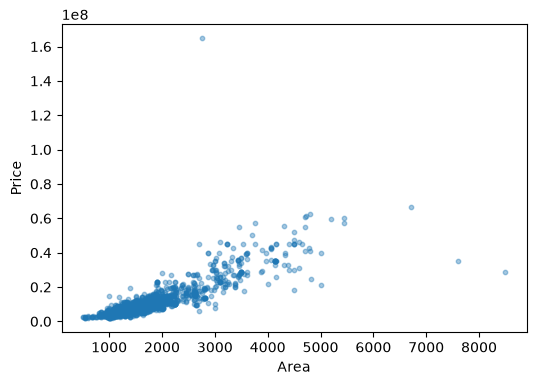

In [ ]:
# We use a scatter plot to see if there is any other info to be gained from our data
plt.figure(figsize=(6, 4))
plt.scatter(df_clean["Area"], df_clean["Price"], alpha=0.4, s=10)
plt.xlabel("Area")
plt.ylabel("Price")
plt.show()

In [ ]:
# We also remove duplicates 
df_clean = df_clean.drop_duplicates()
print(df_clean.shape)

#And remove the outlier, the value was far outside the normal range 
df_clean = df_clean[df_clean['Price'] < 165000000]
print(df_clean.shape,df_clean.describe())

(1844, 39)
(1843, 39)               Price         Area  No. of Bedrooms       Resale  \
count  1.843000e+03  1843.000000      1843.000000  1843.000000   
mean   1.018557e+07  1679.073250         2.654910     0.259902   
std    8.578173e+06   767.927228         0.686667     0.438700   
min    2.000000e+06   500.000000         1.000000     0.000000   
25%    4.958000e+06  1183.000000         2.000000     0.000000   
50%    7.998000e+06  1510.000000         3.000000     0.000000   
75%    1.120000e+07  1878.500000         3.000000     1.000000   
max    6.640000e+07  8500.000000         8.000000     1.000000   

       MaintenanceStaff    Gymnasium  SwimmingPool  LandscapedGardens  \
count       1843.000000  1843.000000   1843.000000        1843.000000   
mean           0.113945     0.474769      0.444384           0.355399   
std            0.317830     0.499499      0.497032           0.478764   
min            0.000000     0.000000      0.000000           0.000000   
25%            0.0

# Summary Statistics 

              Price         Area  No. of Bedrooms  ShoppingMall       School
count  1.843000e+03  1843.000000      1843.000000   1843.000000  1843.000000
mean   1.018557e+07  1679.073250         2.654910      0.072165     0.041237
std    8.578173e+06   767.927228         0.686667      0.258831     0.198892
min    2.000000e+06   500.000000         1.000000      0.000000     0.000000
25%    4.958000e+06  1183.000000         2.000000      0.000000     0.000000
50%    7.998000e+06  1510.000000         3.000000      0.000000     0.000000
75%    1.120000e+07  1878.500000         3.000000      0.000000     0.000000
max    6.640000e+07  8500.000000         8.000000      1.000000     1.000000


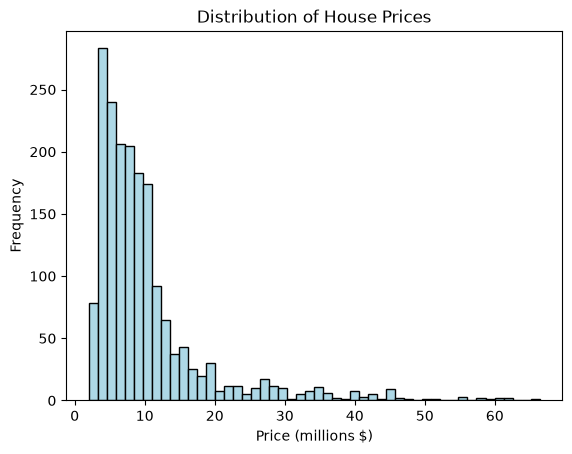

In [ ]:
statistics = df_clean[['Price','Area','No. of Bedrooms','ShoppingMall','School']].describe()
print(statistics)

# Here we plot the histogram 
plt.hist(df_clean['Price']/ 1000000, bins=50, histtype = "bar", edgecolor = "black", color = "lightblue")
plt.xlabel("Price (millions $)")
plt.ylabel("Frequency")
plt.title("Distribution of House Prices")
plt.show()



In [ ]:
# The data appears to be very right skewed. 

# To verify this we now test for normality
price = df_clean['Price']

# Skewness and kurtosis checks 
print('Skew:', stats.skew(price))
print('Excess kurtosis:', stats.kurtosis(price))

# For the test of normality, we choose the Jarque-Bera Test. 
# We chose this test as it is an asymptotic goodness of fit test.
# Making it appropriate considering the skewed histogram and sufficient sample size (n=1844)


#H0: Prices follow a normal Distribution 
#H1: The prices do not follow a normal distrubtion 

print(stats.jarque_bera(price))

# test statistic = 9315.39
# p-value ≈ 0.0, the null hypothesis is rejected. 

Skew: 2.7783245321932535
Excess kurtosis: 9.509524545465892
SignificanceResult(statistic=np.float64(9315.397878498234), pvalue=np.float64(0.0))


 $H0$: The data is normally distributed, with skewness=0 and kurtosis=3\
 $H1$: The data is normally distributed, with skewness≠0, kurtosis≠3 or both

$$JB = \frac{n}{6}\left(S^2 + \frac{(K-3)^2}{4}\right)$$

Results:<br> 
$JB = 9315.39$\
$JB> \chi^2_{0.95}(2) = 5.991$\
$p$ ≈ 0.00

This verifies that the data is non normal. It is  right-skewed with heavy fails. 

In [ ]:
# Here we choose 2 random variables along with Area 
candidates = df_clean.columns.drop(['Price', 'Area'])
random_cols = df_clean[candidates].sample(n=2, axis=1, random_state=42).columns.tolist()
print(random_cols)
df_small = df_clean[['Price', 'Area'] + random_cols].copy()


['CarParking', 'ClubHouse']


In [ ]:
print(df_small.describe())

              Price         Area   CarParking    ClubHouse
count  1.843000e+03  1843.000000  1843.000000  1843.000000
mean   1.018557e+07  1679.073250     0.475855     0.435703
std    8.578173e+06   767.927228     0.499552     0.495983
min    2.000000e+06   500.000000     0.000000     0.000000
25%    4.958000e+06  1183.000000     0.000000     0.000000
50%    7.998000e+06  1510.000000     0.000000     0.000000
75%    1.120000e+07  1878.500000     1.000000     1.000000
max    6.640000e+07  8500.000000     1.000000     1.000000


![Alt text](Table1.png)

# Interpretation
The summary statistics show that the average house price is around 9.8 million, with an average area of 1.600 square units. The average value of CarParking, and ClubHouse, show that rougly half of the houses have a carpark or club house. 


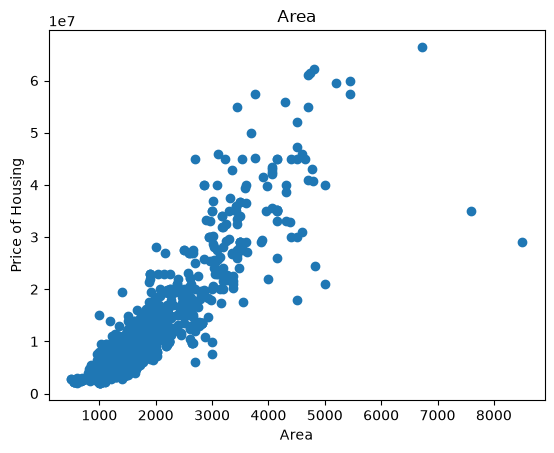

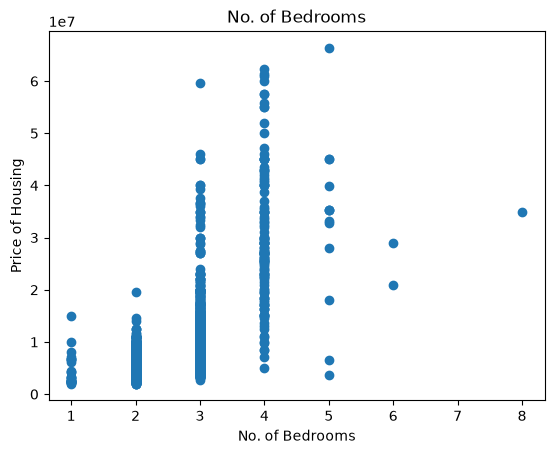

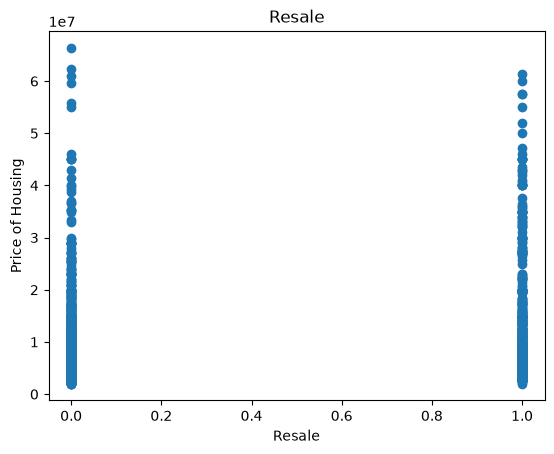

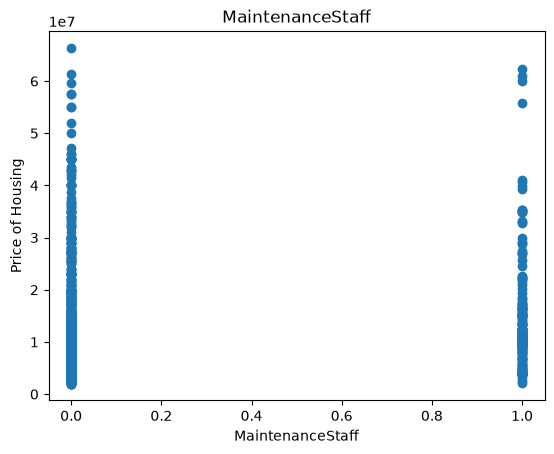

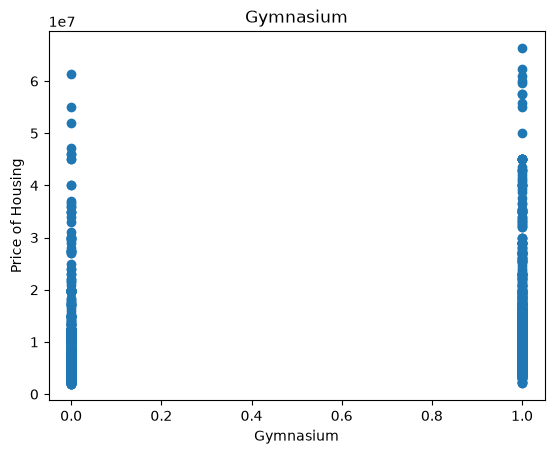

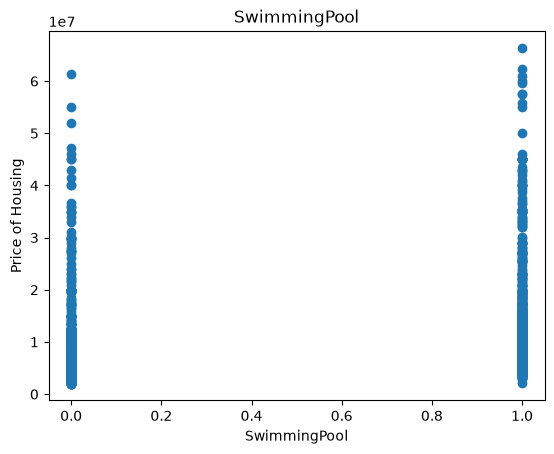

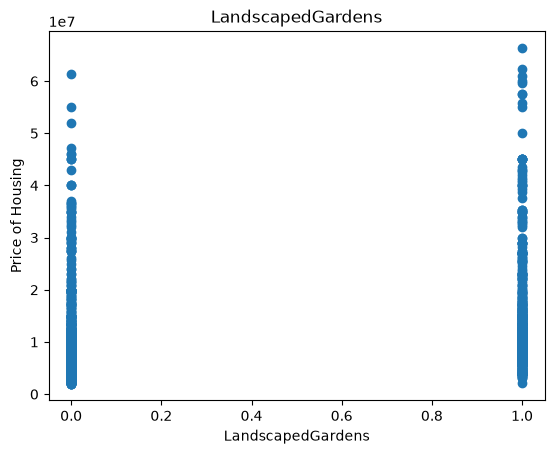

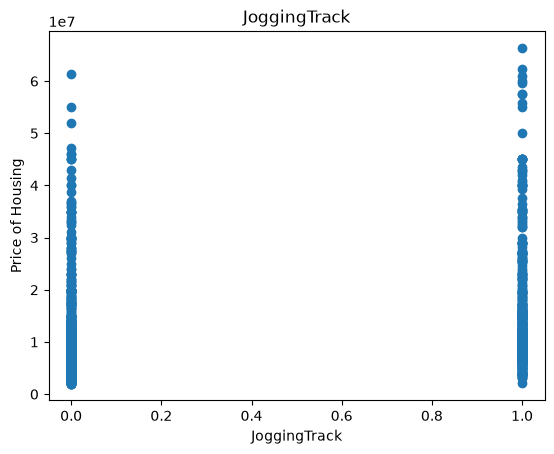

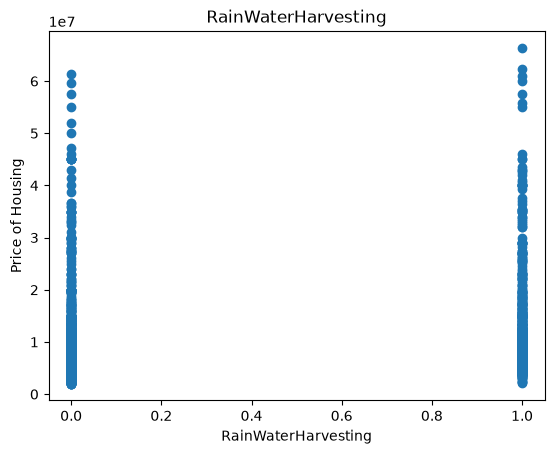

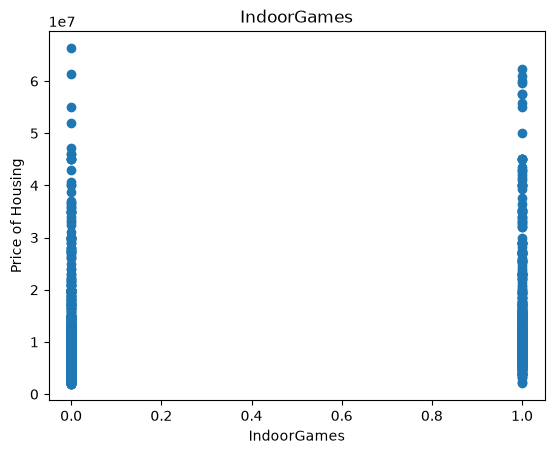

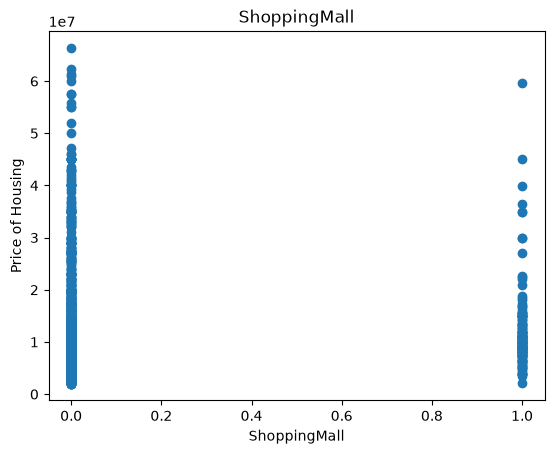

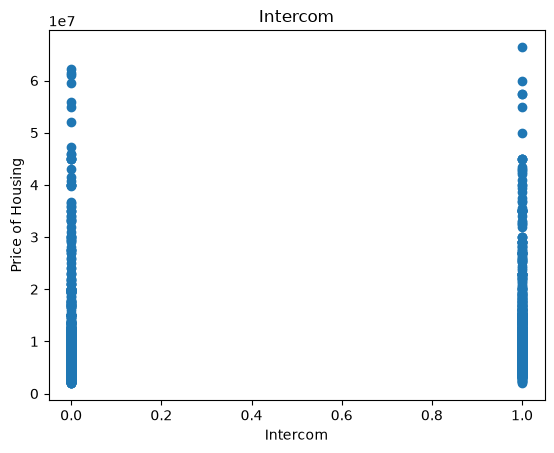

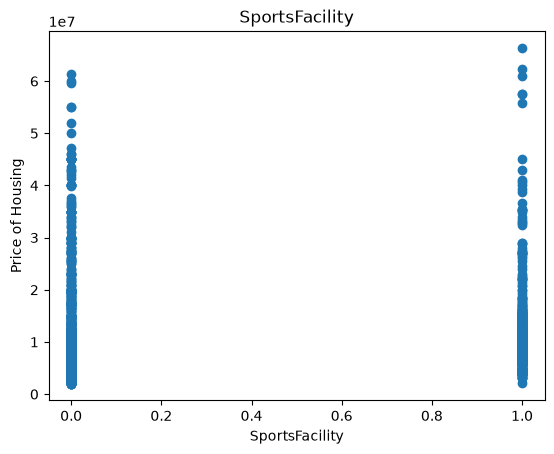

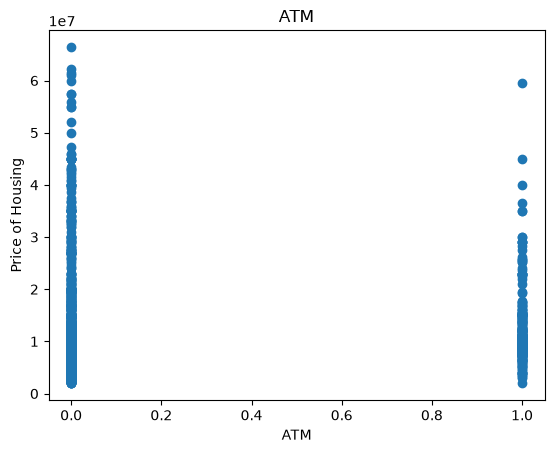

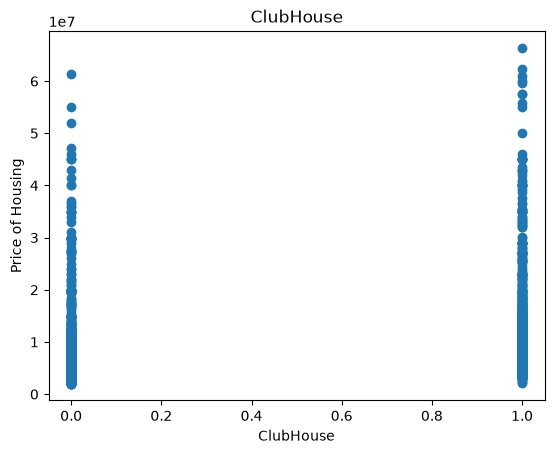

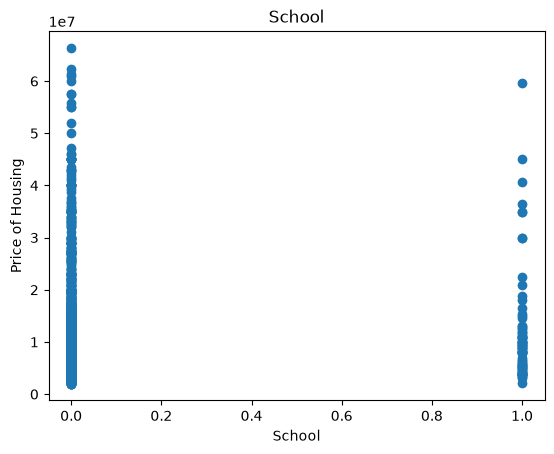

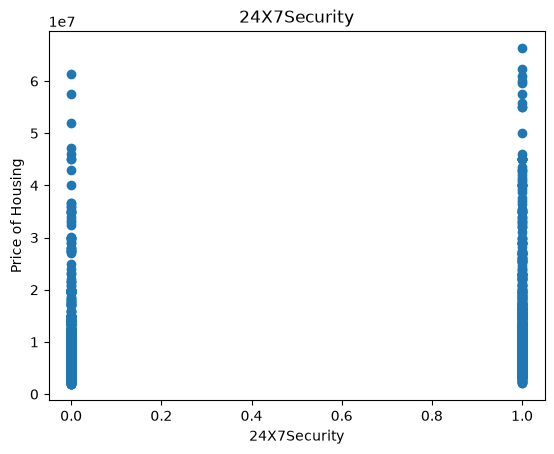

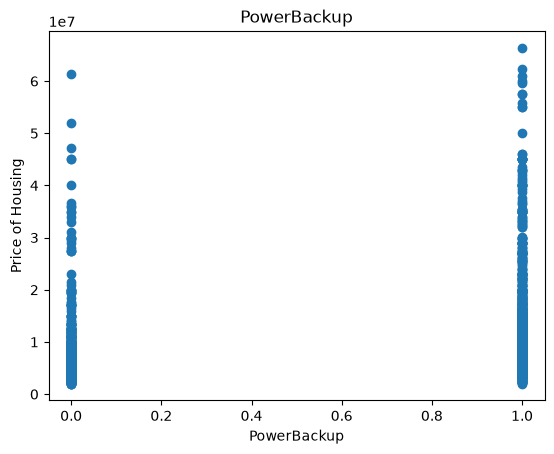

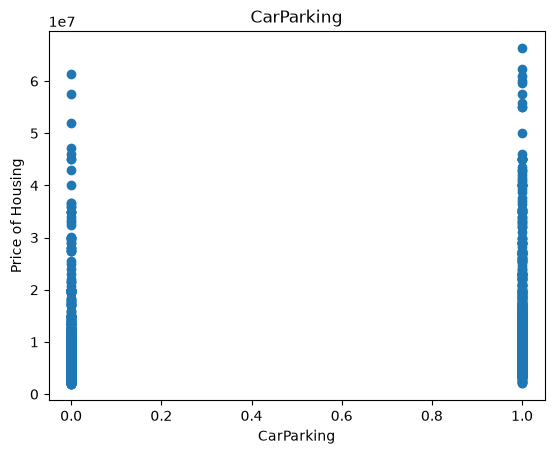

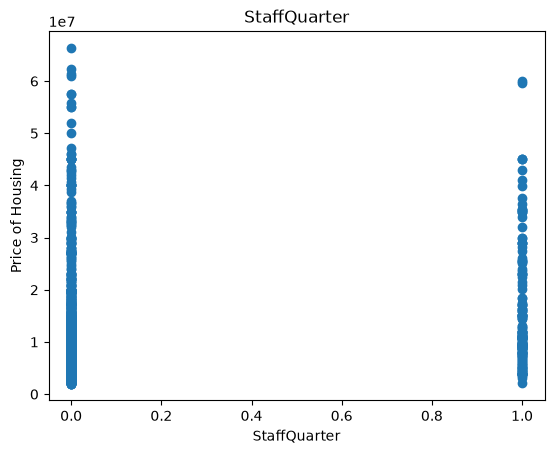

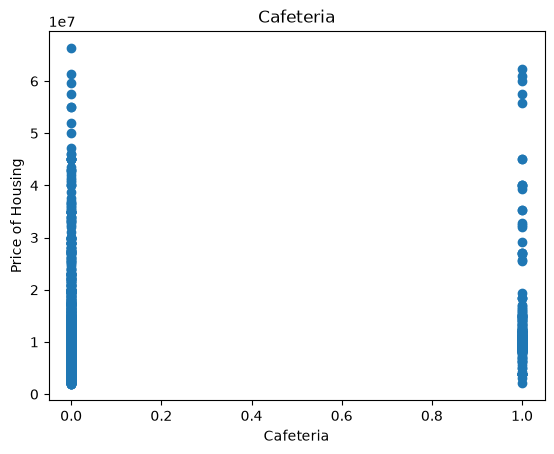

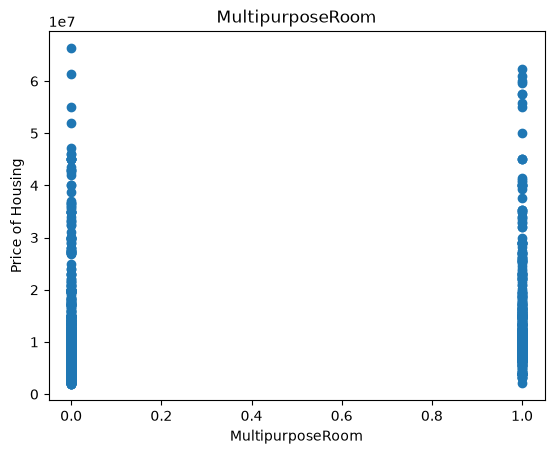

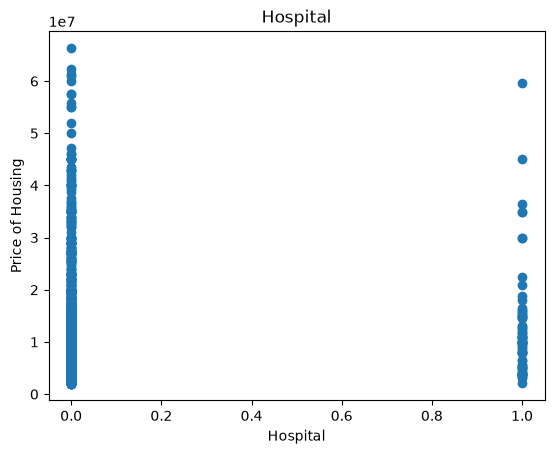

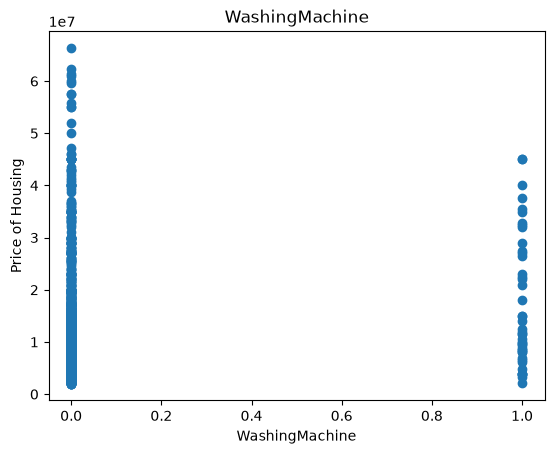

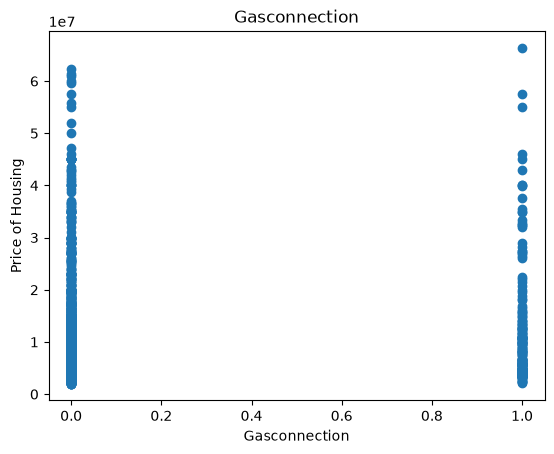

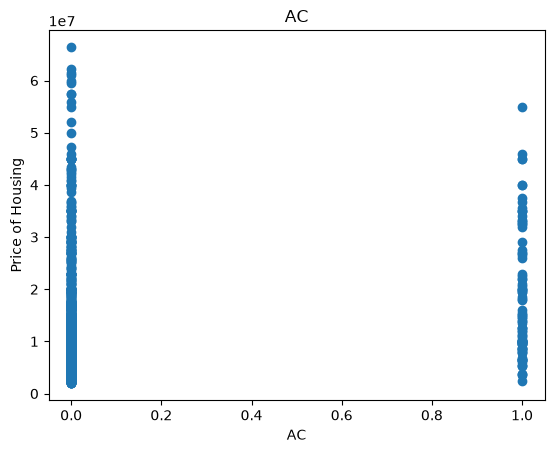

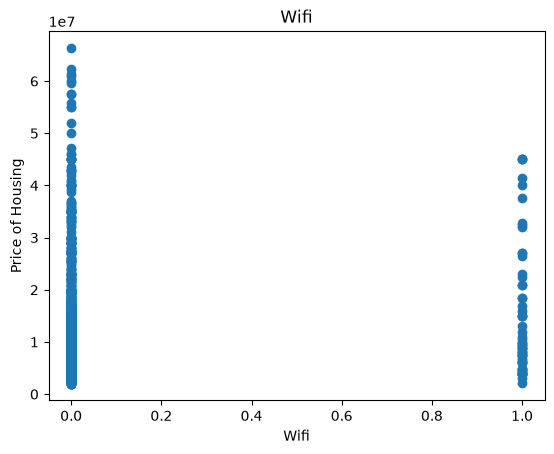

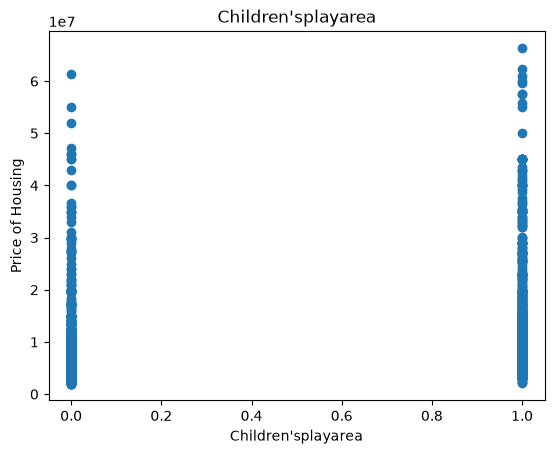

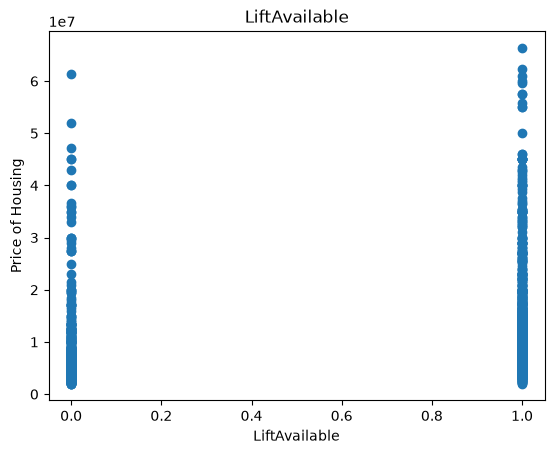

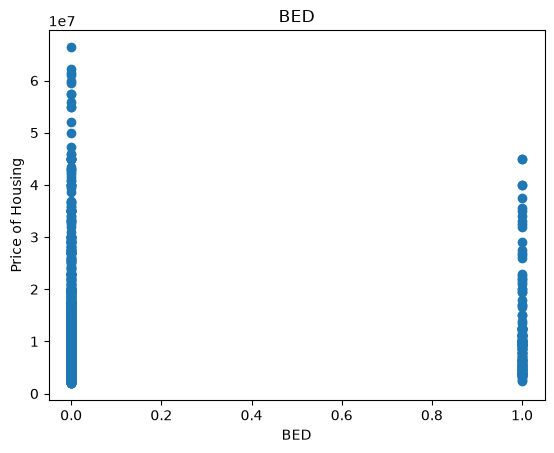

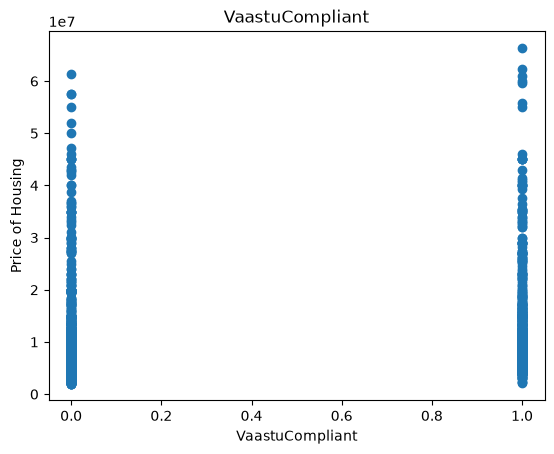

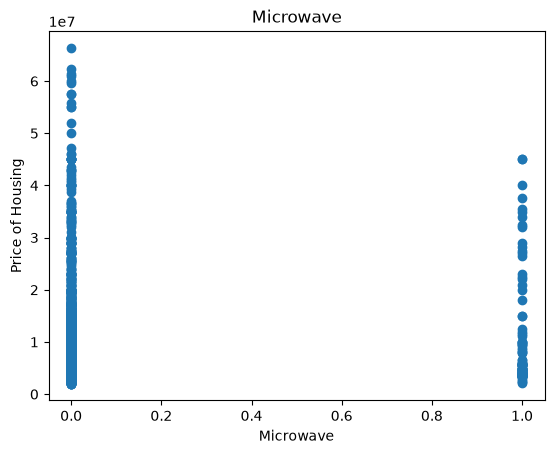

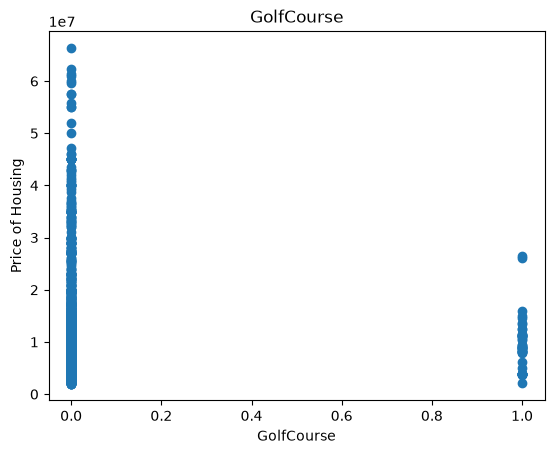

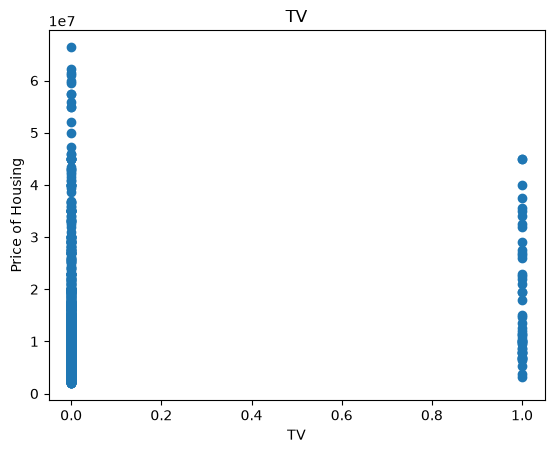

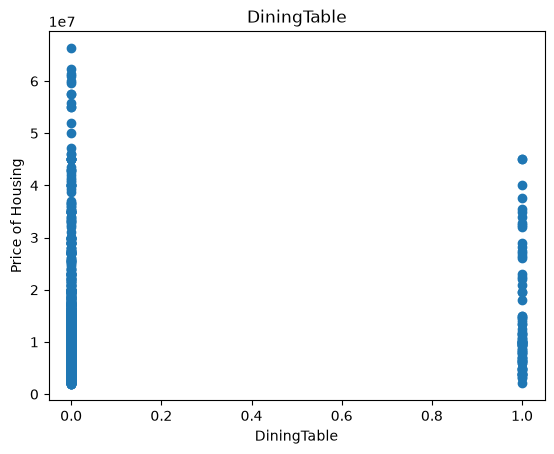

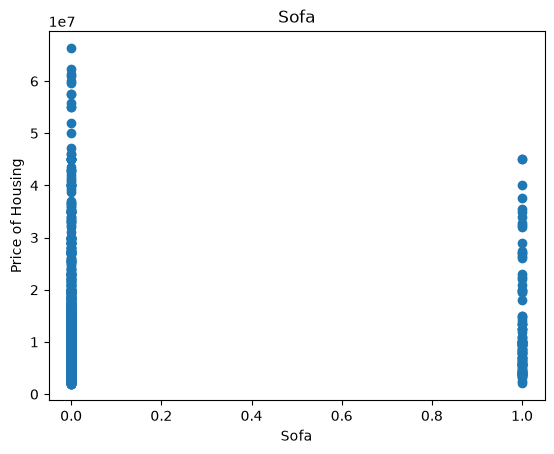

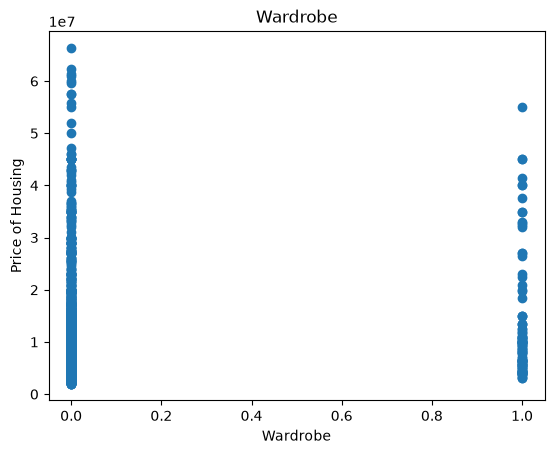

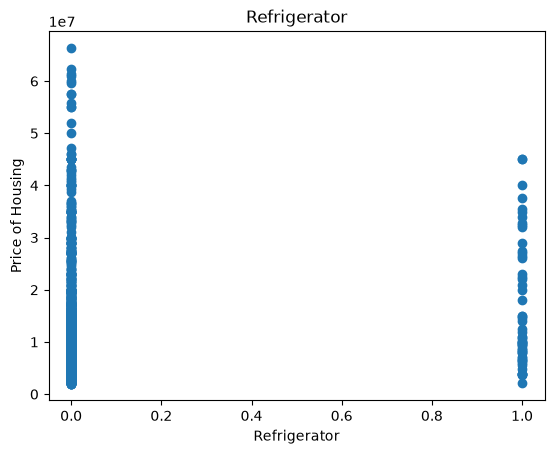

In [ ]:
for label in df_clean.columns[1:]:
    plt.scatter(df_clean[label],df_clean['Price'])
    plt.title(label)
    plt.ylabel("Price of Housing")
    plt.xlabel(label)
    plt.show()

## Training and predicting 

The company allows you to use 3 different models for the housing price:

- Model 1: A multivariate linear regression using all features (benchmark)
- Model 2: Model 1 plus Lasso 
- Model 3: Model 1 plus Ridge

Use a 60/20/20 rule for the training/validation/testing set (set the state fixed). Models 2 - 3 contain **hyperparameters** which you need to tune. In general, do **NOT** use any cross-validation techniques. Instead do the following for Model 2 and 3: Make a vector of different values of the hyperparameter; then create a loop and estimate the ML models using the correct data. Make and show a plot of an appropriate loss function against the different values of the hyperparameter. 

**Important:** Make sure that your features are standardized!

## Deliverables
- Make Table 2 with parameter estimation results of Model 1. Report the constant, the first 5 coefficients (with their standard errors) and the R-squared. Interpret the coefficients related to *Area* and *MaintenanceStaff*. 
- An explanation, accompanied by tables or figures about the hyperparameters you will use for Model 2 and 3. 
- Table 3 with MAPE and MSPE of the predicted housing prices in the testing set.
- Take the best model and test whether the squared prediction errors are statistically different from the benchmark model (by the Diebold Mariano test). What is your conclusion?


# Model 1: Linear Regression

In [ ]:
def data_prep(data,label,seed=42, scale=True):
    # Setting the X and Y variables
    y = data['Price']
    X = data.drop(columns=['Price']).astype(float)

    # Splitting the Training, Validation, and Testing Data
    X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, random_state=seed)
    X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=seed)
    print(f"[{label}] split sizes:", len(X_train), len(X_val), len(X_test))

    # Applying the Scaler (fit on train only)
    if scale: 
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train)
        X_val = scaler.transform(X_val)
        X_test = scaler.transform(X_test)

    return X_train, X_val, X_test, y_train, y_val, y_test

X_clean = data_prep(df_clean, "Original",seed=42)



[Original] split sizes: 1105 369 369


In [ ]:
# We create a function that runs the linear regression fit from sklearn and outputs a table with the first 5 coefficients 
def run_linreg(prepared, label, feature_names, n_coefs=5):
    X_train, X_val, X_test, y_train, y_val, y_test = prepared
    X_train = np.asarray(X_train, dtype=float)
    X_val   = np.asarray(X_val, dtype=float)
    y_train = np.asarray(y_train, dtype=float)
    y_val   = np.asarray(y_val, dtype=float)

    # Estimate the linear regression function with sklearn
    linreg = LinearRegression().fit(X_train, y_train)
    test_pred = linreg.predict(X_test)

    # As robust SEs will converge for homoskedastic errors
    # We choose to calculate the HC3 standard error Variant 
    n, k = X_train.shape
    X_design = np.column_stack([np.ones(n), X_train])      
    resid = y_train - linreg.predict(X_train)
    XtX_inv = np.linalg.pinv(X_design.T @ X_design)

    # We use the following formula for the 
    # "Sandwhich" estimator HC3: (X'X)^-1 X' diag(e^2 / (1-h)^2) X (X'X)^-1
    h = np.einsum("ij,jk,ik->i", X_design, XtX_inv, X_design)
    h = np.clip(h, 0, 1 - 1e-12)                                
    w = resid**2 / (1 - h)**2
    cov = XtX_inv @ (X_design.T * w) @ X_design @ XtX_inv
    se = np.sqrt(np.diag(cov))

    #Outputting the table 
    coef_table = pd.DataFrame(
        {"coef": np.r_[linreg.intercept_, linreg.coef_], "std_err": se},
        index=["const"] + list(feature_names),
    ).head(n_coefs + 1)

    results = {
        "train_r2": linreg.score(X_train, y_train),
        "test_mse": mean_squared_error(y_test, test_pred),
        "test_mae": mean_absolute_error(y_test, test_pred),
        "test_r2": linreg.score(X_test, y_test),
        "test_pred": test_pred,
        "non-zero coef": int(np.sum(linreg.coef_ != 0))
    }

    print(f"[{label}] constant and first {n_coefs} coefficients:")
    print(coef_table.round(4).to_string())
    print(f"[{label}] training R²: {results['train_r2']:.4f}")
    print(f"[{label}] non-zero coefficients: {results['non-zero coef']:.0f}")
    print(f"[{label}] test MSE: {results['test_mse']:.4f}")
    print(f"[{label}] test MAE: {results['test_mae']:.4f}")
    print(f"[{label}] test R²:  {results['test_r2']:.4f}\n")

    results["coef_table"] = coef_table
    results["model"] = linreg
    return results


In [ ]:
# Calculating the first 5 coefficients for the base case 
res_clean = run_linreg(X_clean, "df_clean", df_clean.drop(columns=["Price"]).columns)

latex = res_clean["coef_table"].round(2).to_latex(
    float_format="{:,.2f}".format,
    caption="Linear regression results for df\\_out",
    label="tab:linreg_out",
)
print(latex)

[df_clean] constant and first 5 coefficients:
                          coef      std_err
const             9.998051e+06  110181.5043
Area              7.949010e+06  401441.2444
No. of Bedrooms  -1.077603e+06  272569.0100
Resale            5.499945e+05  150376.7554
MaintenanceStaff -3.749063e+05  157101.8725
Gymnasium        -5.496697e+05  340565.4761
[df_clean] training R²: 0.8218
[df_clean] non-zero coefficients: 38
[df_clean] test MSE: 20026582571583.3281
[df_clean] test MAE: 2402933.5194
[df_clean] test R²:  0.7767

\begin{table}
\caption{Linear regression results for df\_out}
\label{tab:linreg_out}
\begin{tabular}{lrr}
\toprule
 & coef & std_err \\
\midrule
const & 9,998,050.65 & 110,181.50 \\
Area & 7,949,010.11 & 401,441.24 \\
No. of Bedrooms & -1,077,602.64 & 272,569.01 \\
Resale & 549,994.53 & 150,376.76 \\
MaintenanceStaff & -374,906.29 & 157,101.87 \\
Gymnasium & -549,669.70 & 340,565.48 \\
\bottomrule
\end{tabular}
\end{table}



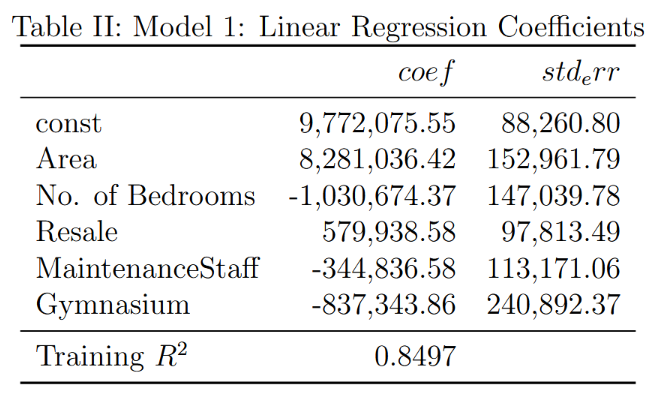


# Interpretation 

The predicted multivariate regression shows that the predicted base price of a house is around 9.77 million dollars. The area increases the price by 8.2 million per. Each additional bedroom reduces the predicted price by 1.03 million. If the house has been resold, the value increases by around 580 thousand. The presence of Maintenence staff reduces the property price by 340 thousand. I predict that this is because 

# Model 2 Lasso

In [ ]:
def run_lasso(prepared, label, feature_names=None, n_alphas=50, decades=4, max_iter=50000):
    # We repeat the step of turning the data into arrays 
    X_train, X_val, X_test, y_train, y_val, y_test = prepared
    X_train, X_val, X_test = (np.asarray(a, dtype=float) for a in (X_train, X_val, X_test))
    y_train, y_val, y_test = (np.asarray(a, dtype=float) for a in (y_train, y_val, y_test))
    n, k = X_train.shape
    # We include this so we can match the feature names in the printout
    if feature_names is not None:
        assert len(feature_names) == k, "feature_names must match the number of columns"

    # Here we centre the data 
    Xc = X_train - X_train.mean(axis=0)
    # alpha_max: smallest alpha at which all coefficients are zero
    alpha_max = np.max(np.abs(Xc.T @ (y_train - y_train.mean()))) / n
    log_hi, log_lo = np.log10(alpha_max), np.log10(alpha_max) - decades

    # Step 1 is estimating the Lasso regression on the training data 
    # We chose to start with alpha 1.0 as this is the scikit default 
    starting_alpha = 1.0
    init_model = Lasso(alpha=starting_alpha, max_iter=max_iter).fit(X_train, y_train)
    init_val_mse = mean_squared_error(y_val, init_model.predict(X_val))
    print(f"[{label}] starting alpha: {starting_alpha:.4g} -> validation MSE: {init_val_mse:.4f}")

    # Step 2: optimise alpha on the validation data (models are fitted on training data only)
    alphas = np.logspace(log_lo, log_hi, n_alphas)
    train_mses, val_mses = [], []
    for a in alphas:
        m = Lasso(alpha=a, max_iter=max_iter).fit(X_train, y_train)
        train_mses.append(mean_squared_error(y_train, m.predict(X_train)))
        val_mses.append(mean_squared_error(y_val, m.predict(X_val)))
    best_idx = int(np.argmin(val_mses))
    best_alpha = alphas[best_idx]
    if best_idx == 0:
        print(f"[{label}] WARNING: best alpha is at the small end of the grid, consider increasing `decades`.")
    elif best_idx == n_alphas - 1:
        print(f"[{label}] NOTE: best alpha is alpha_max, so lasso does not beat the intercept-only model.")

    # Step 3: refit at the best alpha and evaluate once on the test data
    best_model = Lasso(alpha=best_alpha, max_iter=max_iter).fit(X_train, y_train)
    test_pred = best_model.predict(X_test)
    test_mse = mean_squared_error(y_test, test_pred)
    test_mae = mean_absolute_error(y_test, test_pred)
    test_r2 = r2_score(y_test, test_pred)
    n_nonzero = int(np.sum(best_model.coef_ != 0))

    results = {
        "alpha": best_alpha,
        "n_nonzero": n_nonzero,
        "test_mse": test_mse,
        "test_mae": test_mae,
        "test_r2": test_r2,
        "test_pred": test_pred,
        "coef": pd.Series(best_model.coef_,
                          index=list(feature_names) if feature_names is not None else None),
    }

    # Plot: training and validation MSE against alpha
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(alphas, train_mses, marker="o", ms=3, label="Training MSE")
    ax.plot(alphas, val_mses, marker="o", ms=3, label="Validation MSE")
    ax.axvline(best_alpha, color="grey", linestyle="--", label=f"Best alpha = {best_alpha:.3g}")
    ax.set_xscale("log")
    ax.set_xlabel("alpha (log scale)")
    ax.set_ylabel("MSE")
    ax.set_title(f"Lasso: loss vs alpha [{label}]")
    ax.legend()
    ax.grid(True, alpha=0.3)

    print(f"[{label}] best alpha:             {best_alpha:.4g}")
    print(f"[{label}] non-zero coefficients:  {n_nonzero} of {k}")
    print(f"[{label}] test MSE:               {test_mse:.4f}")
    print(f"[{label}] test MAE:               {test_mae:.4f}")
    print(f"[{label}] test R²:                {test_r2:.4f}\n")

    if feature_names is not None:
        coefs = results["coef"]
        nz = coefs[coefs != 0]
        print(f"[{label}] non-zero coefficients (sorted by absolute size):")
        print(nz.reindex(nz.abs().sort_values(ascending=False).index).to_string(), "\n")

    return results, best_model, pd.DataFrame({"alpha": alphas, "train_mse": train_mses, "val_mse": val_mses})

# Model 3 Ridge 

In [ ]:
# We perform the same steps as above but now for the Ridge Regression 
def run_ridge(prepared, label, feature_names=None, n_alphas=50, decades=10, max_iter=50000):
    X_train, X_val, X_test, y_train, y_val, y_test = prepared
    X_train, X_val, X_test = (np.asarray(a, dtype=float) for a in (X_train, X_val, X_test))
    y_train, y_val, y_test = (np.asarray(a, dtype=float) for a in (y_train, y_val, y_test))
    n, k = X_train.shape

    if feature_names is not None:
        assert len(feature_names) == k, "feature_names must match the number of columns"

    Xc = X_train - X_train.mean(axis=0)
    alpha_max = np.max(np.abs(Xc.T @ (y_train - y_train.mean()))) / n
    log_hi, log_lo = np.log10(alpha_max), np.log10(alpha_max) - decades

    starting_alpha = 1.0
    init_model = Lasso(alpha=starting_alpha, max_iter=max_iter).fit(X_train, y_train)
    init_val_mse = mean_squared_error(y_val, init_model.predict(X_val))
    print(f"[{label}] starting alpha: {starting_alpha:.4g} -> validation MSE: {init_val_mse:.4f}")

    # Step 2: optimise alpha on the validation data (models are fitted on training data only)
    alphas = np.logspace(log_lo, log_hi, n_alphas)
    train_mses, val_mses = [], []
    for a in alphas:
        m = Ridge(alpha=a, max_iter=max_iter).fit(X_train, y_train)
        train_mses.append(mean_squared_error(y_train, m.predict(X_train)))
        val_mses.append(mean_squared_error(y_val, m.predict(X_val)))
    best_idx = int(np.argmin(val_mses))
    best_alpha = alphas[best_idx]
    if best_idx == 0:
        print(f"[{label}] WARNING: best alpha is at the small end of the grid, consider increasing `decades`.")
    elif best_idx == n_alphas - 1:
        print(f"[{label}] NOTE: best alpha is alpha_max, so lasso does not beat the intercept-only model.")

    # Step 3: refit at the best alpha and evaluate once on the test data
    best_model = Ridge(alpha=best_alpha, max_iter=max_iter).fit(X_train, y_train)
    test_pred = best_model.predict(X_test)
    test_mse = mean_squared_error(y_test, test_pred)
    test_mae = mean_absolute_error(y_test, test_pred)
    test_r2 = r2_score(y_test, test_pred)
    n_nonzero = int(np.sum(best_model.coef_ != 0))
    
    results = {
        "alpha": best_alpha,
        "n_nonzero": n_nonzero,
        "test_mse": test_mse,
        "test_mae": test_mae,
        "test_r2": test_r2,
        "test_pred": test_pred,
        "coef": pd.Series(best_model.coef_,
                          index=list(feature_names) if feature_names is not None else None),
    }

    # Plot: training and validation MSE against alpha
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(alphas, train_mses, marker="o", ms=3, label="Training MSE")
    ax.plot(alphas, val_mses, marker="o", ms=3, label="Validation MSE")
    ax.axvline(best_alpha, color="grey", linestyle="--", label=f"Best alpha = {best_alpha:.3g}")
    ax.set_xscale("log")
    ax.set_xlabel("alpha (log scale)")
    ax.set_ylabel("MSE")
    ax.set_title(f"Ridge: loss vs alpha [{label}]")
    ax.legend()
    ax.grid(True, alpha=0.3)

    print(f"[{label}] best alpha (Ridge):             {best_alpha:.4g}")
    print(f"[{label}] non-zero coefficients (Ridge):  {n_nonzero} of {k}")
    print(f"[{label}] test MSE (Ridge):               {test_mse:.4f}")
    print(f"[{label}] test MAE (Ridge):               {test_mae:.4f}")
    print(f"[{label}] test R² (Ridge):                {test_r2:.4f}\n")

    if feature_names is not None:
        coefs = results["coef"]
        nz = coefs[coefs != 0]
        print(f"[{label}] non-zero coefficients (sorted by absolute size):")
        print(nz.reindex(nz.abs().sort_values(ascending=False).index).to_string(), "\n")

    return results, best_model, pd.DataFrame({"alpha": alphas, "train_mse": train_mses, "val_mse": val_mses})

[Baseline Linreg] constant and first 5 coefficients:
                          coef      std_err
const             9.998051e+06  110181.5043
Area              7.949010e+06  401441.2444
No. of Bedrooms  -1.077603e+06  272569.0100
Resale            5.499945e+05  150376.7554
MaintenanceStaff -3.749063e+05  157101.8725
Gymnasium        -5.496697e+05  340565.4761
[Baseline Linreg] training R²: 0.8218
[Baseline Linreg] non-zero coefficients: 38
[Baseline Linreg] test MSE: 20026582571583.3281
[Baseline Linreg] test MAE: 2402933.5194
[Baseline Linreg] test R²:  0.7767

[Baseline Lasso] starting alpha: 1 -> validation MSE: 12130468944637.7910


[Baseline Lasso] best alpha:             3.169e+04
[Baseline Lasso] non-zero coefficients:  30 of 38
[Baseline Lasso] test MSE:               19980909850067.1289
[Baseline Lasso] test MAE:               2386692.3985
[Baseline Lasso] test R²:                0.7772

[Baseline Lasso] non-zero coefficients (sorted by absolute size):
Area                   7.809444e+06
No. of Bedrooms       -9.099810e+05
Resale                 5.041211e+05
BED                   -4.618736e+05
LandscapedGardens      4.454757e+05
TV                     3.620519e+05
RainWaterHarvesting   -3.619699e+05
MaintenanceStaff      -3.304083e+05
IndoorGames            2.707280e+05
AC                     2.650921e+05
CarParking             2.502949e+05
SportsFacility        -2.420360e+05
ClubHouse              2.352724e+05
VaastuCompliant       -2.225493e+05
PowerBackup            2.077686e+05
Gasconnection          2.064323e+05
Sofa                  -1.868528e+05
JoggingTrack          -1.808262e+05
MultipurposeRoom     

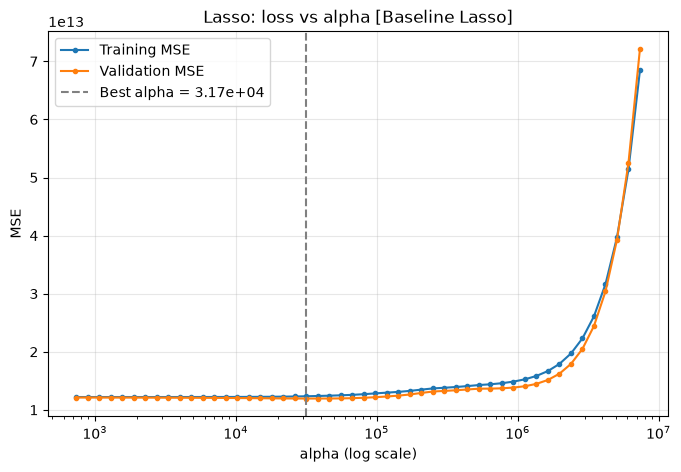

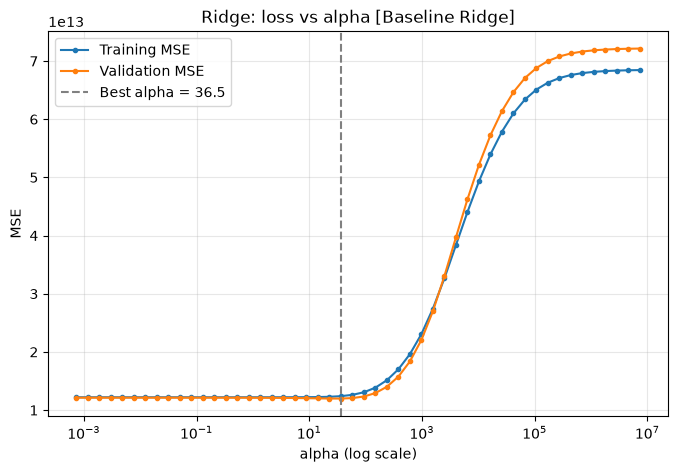

In [ ]:
#Comparing all three models 

res_linear = run_linreg(X_clean, "Baseline Linreg", df_clean.drop(columns=["Price"]).columns)
res_lasso, lasso_model, lasso_loss = run_lasso(
    X_clean, "Baseline Lasso",
    feature_names=df_clean.drop(columns=["Price"]).columns
)
res_ridge, ridge_model, ridge_loss = run_ridge(
    X_clean, "Baseline Ridge",
    feature_names=df_clean.drop(columns=["Price"]).columns
)

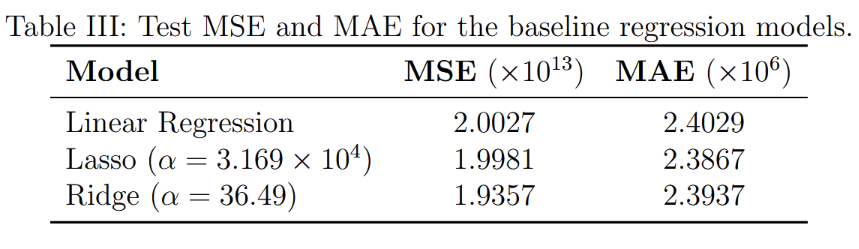

From this it appears that the best model is the Ridge regression based on the MSE. 

In [ ]:
# def run_ridge(prepared, label, n_alphas=50, decades=2, feature_names=None):
#     X_train, X_val, X_test, y_train, y_val, y_test = prepared
#     X_train = np.asarray(X_train, dtype=float)
#     X_val = np.asarray(X_val, dtype=float)
#     y_train = np.asarray(y_train, dtype=float)
#     y_val = np.asarray(y_val, dtype=float)

#     # Alpha grid: Ridge minimises ||y - Xw||^2 + alpha*||w||^2, so the useful range of alpha
#     # is set by the eigenvalues of Xc'Xc (squared singular values of the centred X).
#     # Ridge only starts to matter once alpha is comparable to them.
#     Xc = X_train - X_train.mean(axis=0)
#     sv2 = np.linalg.svd(Xc, compute_uv=False) ** 2
#     lo = max(sv2.min(), sv2.max() * 1e-8)      # guard against near-collinear columns
#     hi = sv2.max()
#     alphas = np.logspace(np.log10(lo) - decades, np.log10(hi) + decades, n_alphas)

#     # Loop over the alphas, fitting on the training data only
#     rows = []
#     for a in alphas:
#         m = Ridge(alpha=a).fit(X_train, y_train)
#         rows.append({
#             "alpha": a,
#             "train_mse": mean_squared_error(y_train, m.predict(X_train)),
#             "val_mse": mean_squared_error(y_val, m.predict(X_val)),
#             "coef_norm": np.linalg.norm(m.coef_),
#         })
#     loss_df = pd.DataFrame(rows)

#     # Best alpha = lowest validation MSE
#     best_idx = int(loss_df["val_mse"].idxmin())
#     best_alpha = loss_df.loc[best_idx, "alpha"]
#     if best_idx in (0, len(alphas) - 1):
#         print(f"[{label}] WARNING: best alpha is at the edge of the grid, consider increasing `decades`.")

#     # Refit at the best alpha and collect validation metrics
#     best_model = Ridge(alpha=best_alpha).fit(X_train, y_train)
#     val_pred = best_model.predict(X_val)
#     results = {
#         "alpha": best_alpha,
#         "val_mse": mean_squared_error(y_val, val_pred),
#         "val_mae": mean_absolute_error(y_val, val_pred),
#         "val_r2": best_model.score(X_val, y_val),
#     }

#     # Plots: loss vs alpha, and coefficient shrinkage vs alpha
#     fig, (ax1) = plt.subplots(1, 1, figsize=(13, 5))
#     ax1.plot(loss_df["alpha"], loss_df["train_mse"], marker="o", ms=3, label="Training MSE")
#     ax1.plot(loss_df["alpha"], loss_df["val_mse"], marker="o", ms=3, label="Validation MSE")
#     ax1.axvline(best_alpha, color="grey", linestyle="--", label=f"Best alpha = {best_alpha:.3g}")
#     ax1.set_xscale("log")
#     ax1.set_xlabel("alpha (log scale)")
#     ax1.set_ylabel("MSE")
#     ax1.set_title(f"Ridge: loss vs alpha [{label}]")
#     ax1.legend()
#     ax1.grid(True, alpha=0.3)


#     print(f"[{label}] Ridge best alpha: {best_alpha:.4g} (grid index {best_idx} of {len(alphas) - 1})")
#     print(f"[{label}] validation MSE: {results['val_mse']:.4f}")
#     print(f"[{label}] validation MAE: {results['val_mae']:.4f}")
#     print(f"[{label}] validation R²:  {results['val_r2']:.4f}\n")

#     if feature_names is not None:
#         coefs = pd.Series(best_model.coef_, index=list(feature_names))
#         print(f"[{label}] coefficients at best alpha:")
#         print(coefs.sort_values().to_string(), "\n")

#     return results, best_model, loss_df

# res_ridge, ridge_model, ridge_loss = run_ridge( X_clean, "Original",
#     feature_names=df_clean.drop(columns=["Price"]).columns,
# )

# Diebold Mariano Test

In [ ]:
test_data = X_clean[-1]
Linear_pred = res_linear['test_pred']
Ridge_pred = res_ridge['test_pred']
Lasso_pred = res_lasso['test_pred']

In [ ]:
# def diebold_mariano(y_true, pred_1, pred_2, h=1, hln_correction=True):
def diebold_mariano(y_true, pred_1, pred_2):
    """
    Diebold-Mariano test on squared-error loss.
    H0: both models have equal expected squared error.
    Negative statistic -> model 1 has lower loss than model 2.
    """ 
    
    y_true = np.asarray(y_true)
    e1 = y_true - np.asarray(pred_1)
    e2 = y_true - np.asarray(pred_2)

    # Calculating using the squared errors 
    d = e1**2 - e2**2            
    T = len(d)
    d_mean = d.mean()

    # Long-run variance of d: gamma_0 + 2 * sum_{k=1}^{h-1} gamma_k
    def autocov(x, k):
        x_c = x - x.mean()
        return np.sum(x_c[k:] * x_c[:T - k]) / T

    lrv = autocov(d, 0) + 2 * sum(autocov(d, k) for k in range(1, 1))

    # The Diebold_Mariano Test statistic
    dm_stat = d_mean / np.sqrt(lrv / T)
    
    p_value = 2 * (1 - stats.norm.cdf(abs(dm_stat)))

    return dm_stat, p_value

pred_lasso  = Lasso_pred  
pred_ridge = Ridge_pred 
pred_linreg = Linear_pred

dm_stat, p_val = diebold_mariano(test_data, pred_linreg, pred_ridge)

print(f"DM statistic(Linear,Ridge): {dm_stat:.4f}")
print(f"p-value(Linear,Ridge):      {p_val:.4f}")

dm_stat, p_val = diebold_mariano(test_data, pred_linreg, pred_lasso)

print(f"DM statistic(Linear,Lasso): {dm_stat:.4f}")
print(f"p-value(Linear,Lasso):      {p_val:.4f}")

DM statistic(Linear,Ridge): 0.5999
p-value(Linear,Ridge):      0.5486
DM statistic(Linear,Lasso): 0.2556
p-value(Linear,Lasso):      0.7982


# Two Sided Diebold-Mariano Test 
Let $e_{\text{Lasso},t}$ and $e_{\text{LR},t}$ be the forecast errors of the two models on test observation

**The loss differential** 

$$d_t = e_{\text{Lasso},t}^2 - e_{\text{LR},t}^2 .$$

**Hypotheses:**

$$H_0: \mathbb{E}[d_t] = 0 \qquad \text{vs.} \qquad H_1: \mathbb{E}[d_t] \neq 0$$

**Test statistic:**

$$DM = \frac{\overline{d}}{\sqrt{\widehat{Var}(\overline{d})}} $$

Results:<br> 
reject $H_0$ if $|DM| > z_{0.025} = 1.96$\
$|DM| = 0.599 < 1.96$\
$p ≈ 0.549 > 0.05$\
The null hypothesis is **not rejected** at the 5% significance level

# Robustness Checks 

[Seed 1] split sizes: 1105 369 369
[Seed 1 Lin] constant and first 5 coefficients:
                          coef      std_err
const             1.028672e+07  117375.3514
Area              8.066040e+06  746785.5948
No. of Bedrooms  -1.023391e+06  287902.3636
Resale            7.670985e+05  182801.9250
MaintenanceStaff -2.062522e+05  156732.2808
Gymnasium        -3.108808e+05  333687.4331
[Seed 1 Lin] training R²: 0.8226
[Seed 1 Lin] non-zero coefficients: 38
[Seed 1 Lin] test MSE: 13378268783420.8340
[Seed 1 Lin] test MAE: 2260973.8563
[Seed 1 Lin] test R²:  0.8364

[Seed 1 Lasso] starting alpha: 1 -> validation MSE: 14401156270538.2012
[Seed 1 Lasso] best alpha:             4.654e+05
[Seed 1 Lasso] non-zero coefficients:  7 of 38
[Seed 1 Lasso] test MSE:               14437678108683.1484
[Seed 1 Lasso] test MAE:               2277308.6996
[Seed 1 Lasso] test R²:                0.8235

[Seed 1 Lasso] non-zero coefficients (sorted by absolute size):
Area            7.177576e+06
Resale  

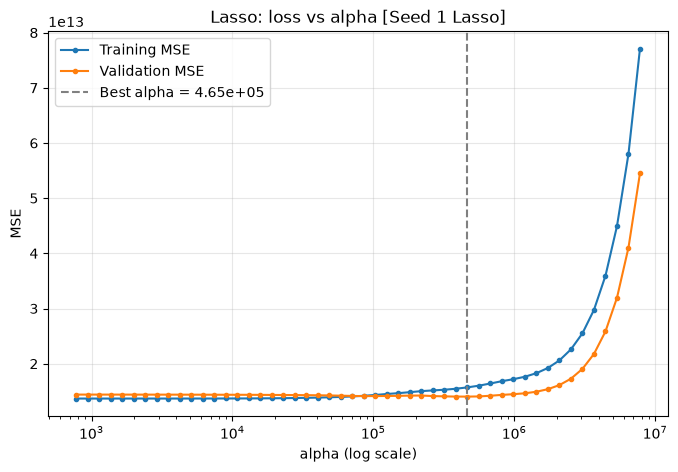

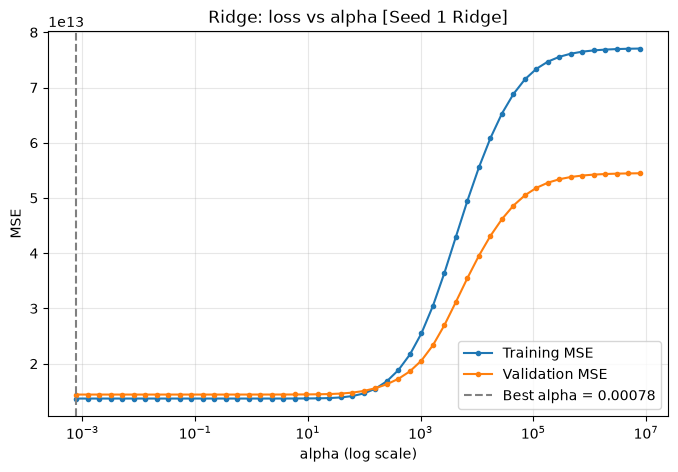

In [ ]:
# Here we rerun the data with a random seed, 140 instead of 42.
# The seed used when calling the functioning is for setting the initial alpha
X_seed1 = data_prep(df_clean, "Seed 1",seed=140)
res_linear_S1 = run_linreg(X_seed1, "Seed 1 Lin", df_clean.drop(columns=["Price"]).columns)
res_lasso_S1, lasso_model, lasso_loss = run_lasso(
    X_seed1, "Seed 1 Lasso",
    feature_names=df_clean.drop(columns=["Price"]).columns,
)
res_ridge_S1, ridge_model, ridge_loss = run_ridge(
    X_seed1, "Seed 1 Ridge",
    feature_names=df_clean.drop(columns=["Price"]).columns,
)

In [ ]:
test_data = X_seed1[-1]
Linear_pred_S1 = res_linear_S1['test_pred']
Lasso_pred_S1 = res_lasso_S1['test_pred']
Ridge_pred_S1 = res_ridge_S1['test_pred']

dm_stat_S1, p_val_S1 = diebold_mariano(test_data,Linear_pred_S1,Ridge_pred_S1)
print(f"DM statistic(Lin,Ridge): {dm_stat_S1:.4f}")
print(f"p-value(Lin,Ridge):      {p_val_S1:.4f}")

dm_stat_S1, p_val_S1 = diebold_mariano(test_data,Linear_pred_S1,Lasso_pred_S1)
print(f"DM statistic(Lin,Lasso): {dm_stat_S1:.4f}")
print(f"p-value(Lin,Lasso)      {p_val_S1:.4f}")

DM statistic(Lin,Ridge): -0.7831
p-value(Lin,Ridge):      0.4336
DM statistic(Lin,Lasso): -1.4967
p-value(Lin,Lasso)      0.1345


[Seed 2] split sizes: 1105 369 369
[Seed 2] constant and first 5 coefficients:
                          coef      std_err
const             1.038870e+07  117630.0561
Area              8.032527e+06  779035.7703
No. of Bedrooms  -7.900410e+05  301540.1109
Resale            8.120358e+05  180906.8852
MaintenanceStaff -3.357677e+05  138528.8732
Gymnasium        -5.819021e+05  309283.1659
[Seed 2] training R²: 0.8205
[Seed 2] non-zero coefficients: 38
[Seed 2] test MSE: 15649174940441.2852
[Seed 2] test MAE: 2388898.8107
[Seed 2] test R²:  0.7749

[Seed 2] starting alpha: 1 -> validation MSE: 11340260091119.4941
[Seed 2] best alpha:             3.345e+04
[Seed 2] non-zero coefficients:  32 of 38
[Seed 2] test MSE:               15647609425652.5117
[Seed 2] test MAE:               2335423.1933
[Seed 2] test R²:                0.7749

[Seed 2] non-zero coefficients (sorted by absolute size):
Area                   7.874990e+06
Resale                 7.394743e+05
No. of Bedrooms       -5.95540

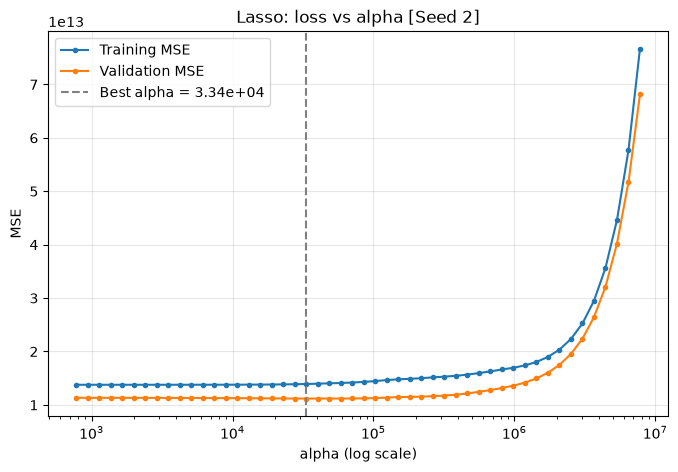

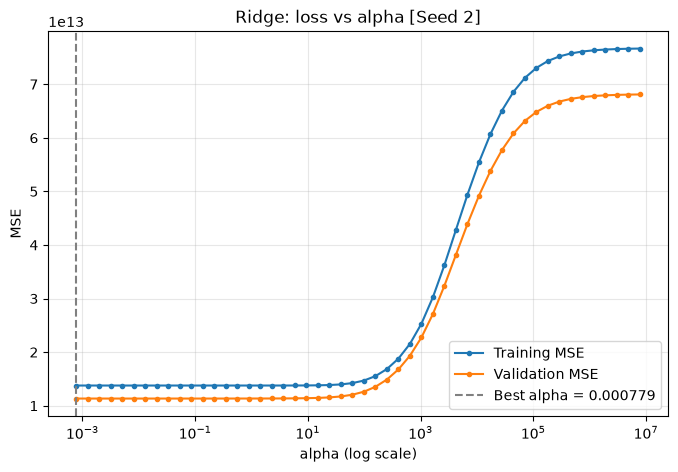

In [ ]:
#Second random seed 
X_seed2 = data_prep(df_clean, "Seed 2",seed=824)
res_linear_S2 = run_linreg(X_seed2, "Seed 2", df_clean.drop(columns=["Price"]).columns)
res_lasso_S2, lasso_model, lasso_loss = run_lasso(X_seed2, "Seed 2",
    feature_names=df_clean.drop(columns=["Price"]).columns,
)
res_ridge_S2, ridge_model, ridge_loss = run_ridge( X_seed2, "Seed 2",
    feature_names=df_clean.drop(columns=["Price"]).columns,
)


In [ ]:
# Diebold-Mariano Tests for Random seed 2 
test_data = X_seed2[-1]
Linear_pred_S2 = res_linear_S2['test_pred']
Lasso_pred_S2 = res_lasso_S2['test_pred']
Ridge_pred_S2 = res_ridge_S2['test_pred']

dm_stat_S2, p_val_S2 = diebold_mariano(test_data,Linear_pred_S2,Ridge_pred_S2)
print(f"DM statistic(Lin,Ridge): {dm_stat_S2:.4f}")
print(f"p-value(Lin,Ridge):      {p_val_S2:.4f}")

dm_stat_S2, p_val_S2 = diebold_mariano(test_data,Linear_pred_S2,Lasso_pred_S2)
print(f"DM statistic(Lin,Lasso): {dm_stat_S2:.4f}")
print(f"p-value(Lin,Lasso)      {p_val_S2:.4f}")

DM statistic(Lin,Ridge): -0.5071
p-value(Lin,Ridge):      0.6121
DM statistic(Lin,Lasso): 0.0081
p-value(Lin,Lasso)      0.9935


[unscaled] split sizes: 1105 369 369
[unscaled] constant and first 5 coefficients:
                          coef      std_err
const            -5.055646e+06  638499.6869
Area              1.104337e+04     557.7126
No. of Bedrooms  -1.617752e+06  409194.3939
Resale            1.260061e+06  344519.5425
MaintenanceStaff -1.137593e+06  476700.5768
Gymnasium        -1.100910e+06  682103.9461
[unscaled] training R²: 0.8218
[unscaled] non-zero coefficients: 38
[unscaled] test MSE: 20026582571583.3477
[unscaled] test MAE: 2402933.5194
[unscaled] test R²:  0.7767

[Unscaled] starting alpha: 1 -> validation MSE: 12130446248067.4062
[Unscaled] best alpha:             3.825e+08
[Unscaled] non-zero coefficients:  1 of 38
[Unscaled] test MSE:               21185812977963.0625
[Unscaled] test MAE:               2559452.2967
[Unscaled] test R²:                0.7638

[Unscaled] non-zero coefficients (sorted by absolute size):
Area    9519.275317 



/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(


[Unscaled] starting alpha: 1 -> validation MSE: 12130446248067.4062
[Unscaled] best alpha (Ridge):             14.26
[Unscaled] non-zero coefficients (Ridge):  38 of 38
[Unscaled] test MSE (Ridge):               20050020838204.0625
[Unscaled] test MAE (Ridge):               2391332.0644
[Unscaled] test R² (Ridge):                0.7764

[Unscaled] non-zero coefficients (sorted by absolute size):
No. of Bedrooms       -1.475115e+06
BED                   -1.356137e+06
TV                     1.339876e+06
Resale                 1.149044e+06
AC                     1.071826e+06
MaintenanceStaff      -9.963233e+05
LandscapedGardens      9.064062e+05
RainWaterHarvesting   -8.507217e+05
IndoorGames            7.118668e+05
Gasconnection          7.112761e+05
ClubHouse              6.770967e+05
CarParking             6.706783e+05
Gymnasium             -6.464723e+05
SportsFacility        -6.363798e+05
SwimmingPool           5.763350e+05
JoggingTrack          -5.690453e+05
MultipurposeRoom       5.

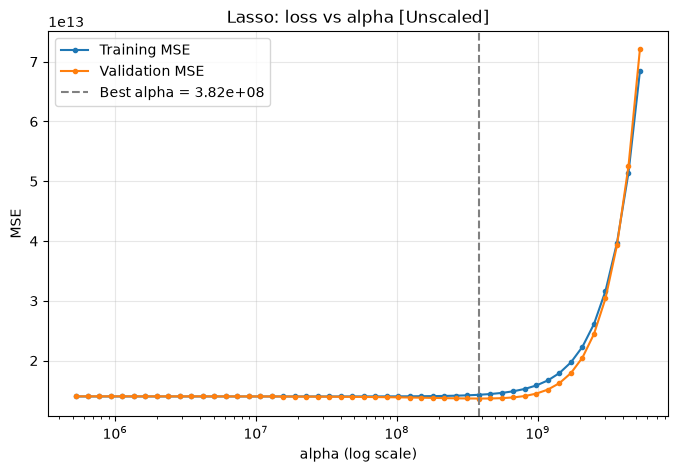

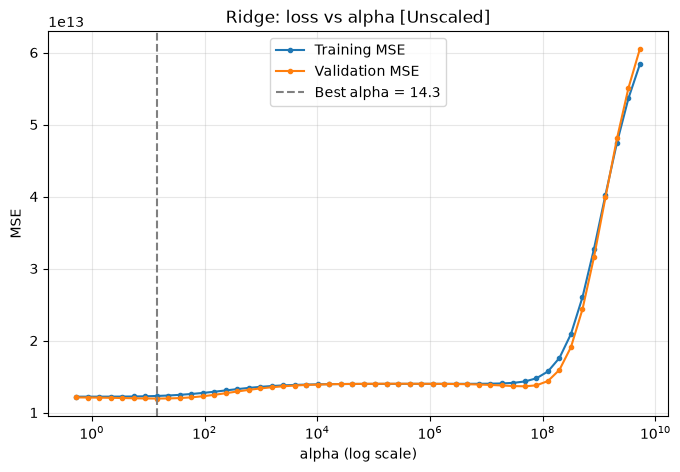

In [ ]:
# Now We set the sacling to false  
X_unscaled = data_prep(df_clean, "unscaled",seed=42,scale=False)
res_linear_u = run_linreg(X_unscaled, "unscaled", df_clean.drop(columns=["Price"]).columns)
res_lasso_u, lasso_model, lasso_loss = run_lasso(X_unscaled, "Unscaled",
    feature_names=df_clean.drop(columns=["Price"]).columns,
)
res_ridge_u, ridge_model, ridge_loss = run_ridge( X_unscaled, "Unscaled",
    feature_names=df_clean.drop(columns=["Price"]).columns,
)


In [ ]:
# Diebold-Mariano Tests for Random seed 2 
test_data = X_unscaled[-1]
Linear_pred_u = res_linear_u['test_pred']
Lasso_pred_u = res_lasso_u['test_pred']
Ridge_pred_u = res_ridge_u['test_pred']

dm_stat_u, p_val_u = diebold_mariano(test_data,Linear_pred_u,Ridge_pred_u)
print(f"DM statistic(Lin,Ridge): {dm_stat_u:.4f}")
print(f"p-value(Lin,Ridge):      {p_val_u:.4f}")

dm_stat_u, p_val_u = diebold_mariano(test_data,Linear_pred_u,Lasso_pred_u)
print(f"DM statistic(Lin,Lasso): {dm_stat_u:.4f}")
print(f"p-value(Lin,Lasso)      {p_val_u:.4f}")

DM statistic(Lin,Ridge): -0.2008
p-value(Lin,Ridge):      0.8409
DM statistic(Lin,Lasso): -0.8678
p-value(Lin,Lasso)      0.3855


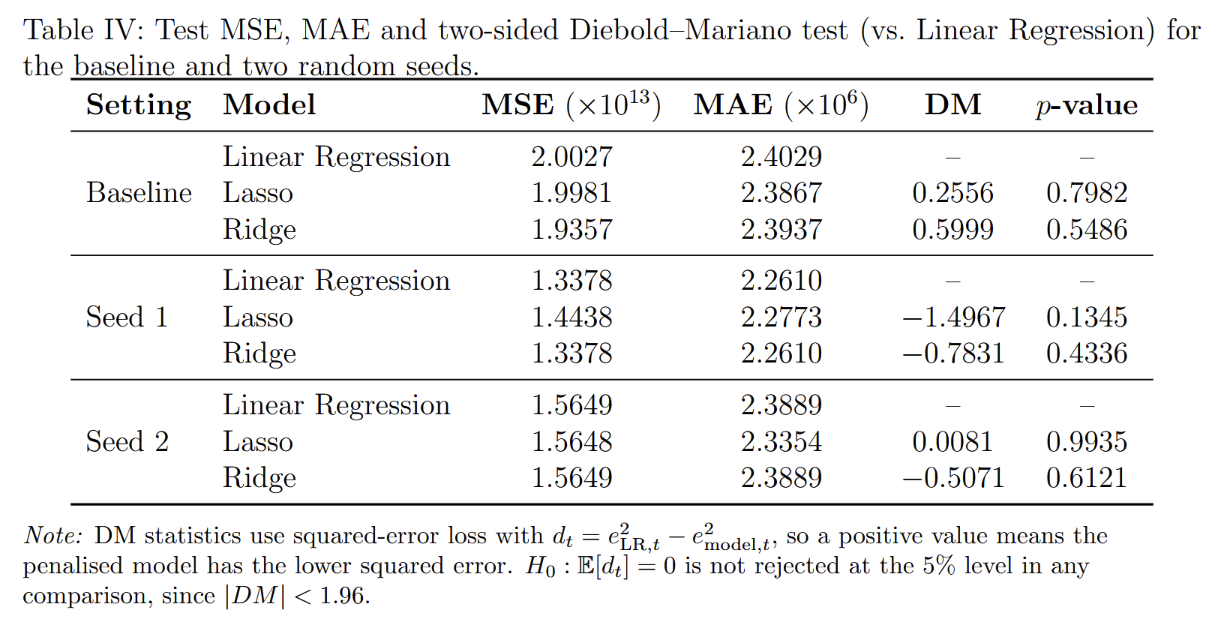

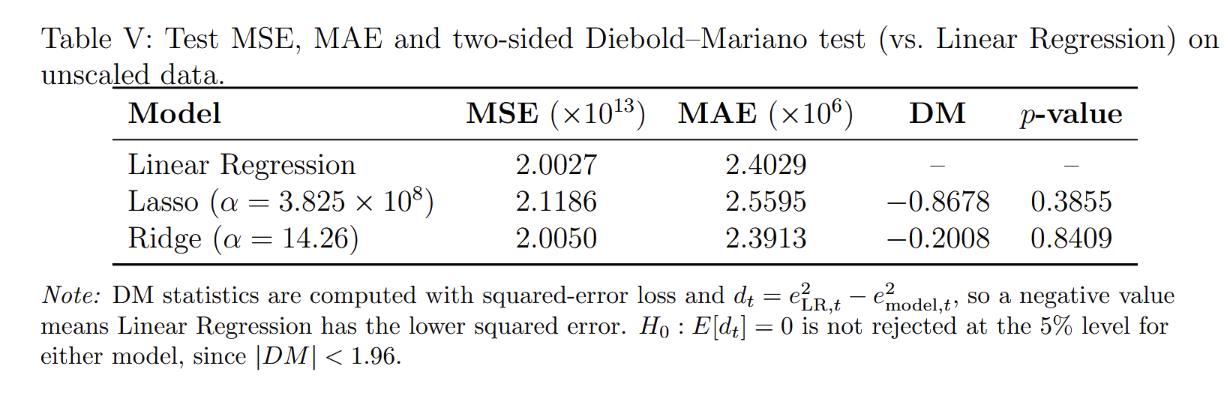

# Model Choice 

I would choose the baseline linear regression model to model housing prices. As there were no significant differences in prediction accuracy for the other 2 models based on the Diebold Mariano Test. It seems the right skewness of prices and small validation data size cause inconsistency in the alpha optimisation, yielding models that are statistically different to the base model. 